# Airbnb Market Lab: a guided walkthrough

An AI-assisted personal project using real Inside Airbnb Albany data. Run the CLI once before this notebook. All results below come from saved analytical outputs or SQL; there is no network call or secret key in this notebook.

**First question:** what does the data actually measure? Listed prices and available calendar states are not realised bookings or revenue. The snapshot archive is dated 2026-09-14, while the listing scrape date is 2026-09-16.


In [1]:
from pathlib import Path
import json
import duckdb
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'configs').exists():
    ROOT = ROOT.parent
OUT = ROOT / 'outputs/albany/2026-09-14'
DB = ROOT / 'data/warehouse/albany/2026-09-14.duckdb'
assert DB.exists(), 'Run python -m airbnb_lab.cli run first.'
results = json.loads((OUT / 'analysis.json').read_text())
quality = json.loads((OUT / 'quality_report.json').read_text())
con = duckdb.connect(str(DB), read_only=True)
pd.Series(results['summary'], name='value').to_frame()


,value
listings,500.000000
hosts,200.000000
reviews,30251.000000
calendar_rows,182500.000000
priced_listings,467.000000
missing_or_nonpositive_price,33.000000
median_price,144.000000
mean_price,292.594433
p90_price,308.000000
top_10pct_host_supply_share,0.442000


## 1. Check the grain before joining

One database is one city/snapshot. Calendar facts are unique on listing ID plus calendar date; review facts have unique review IDs. Large IDs remain strings. A join that changes the fact count indicates a grain error.


In [2]:
display(con.execute('SHOW TABLES').df())
con.execute('''SELECT
  (SELECT count(*) FROM fact_calendar) AS before_join,
  (SELECT count(*) FROM fact_calendar c JOIN dim_listing l ON c.listing_id=l.id) AS after_join
''').df()


,name
0,dim_date
1,dim_host
2,dim_listing
3,dim_neighbourhood
4,fact_calendar
5,fact_review
6,mart_calendar_month
7,mart_neighbourhood
8,snapshot_metadata


,before_join,after_join
0,182500,182500


## 2. Read the quality report

Missing prices stay missing. Similar-title records are candidates for manual review, not deletions. Numeric bathrooms are recovered from explicit descriptions; account tenure is approximate where only duration components are available.


In [3]:
pd.Series(quality, dtype=object).to_frame('observed')

,observed
listings_invalid_keys_removed,0
listings_duplicate_keys_removed,0
negative_listing_prices,0
missing_listing_prices,33
zero_listing_prices,0
bathrooms_recovered_from_text,500
invalid_latitude,0
invalid_longitude,0
invalid_availability_365,0
invalid_review_scores_rating,0


## 3. Compare prices within segments

Only positive-price listings enter these comparisons. Count the priced records and compare room types before attributing differences to neighbourhood. Means can be pulled upward by extreme values.


In [4]:
con.execute('''
SELECT room_type, count(*) AS listings,
       count(*) FILTER (WHERE price > 0) AS priced,
       median(price) FILTER (WHERE price > 0) AS median_price,
       avg(price) FILTER (WHERE price > 0) AS mean_price
FROM dim_listing GROUP BY room_type ORDER BY listings DESC
''').df()


,room_type,listings,priced,median_price,mean_price
0,entire home/apt,352,332,170.0,372.776717
1,private room,147,134,75.0,89.848731
2,shared room,1,1,840.0,840.000000


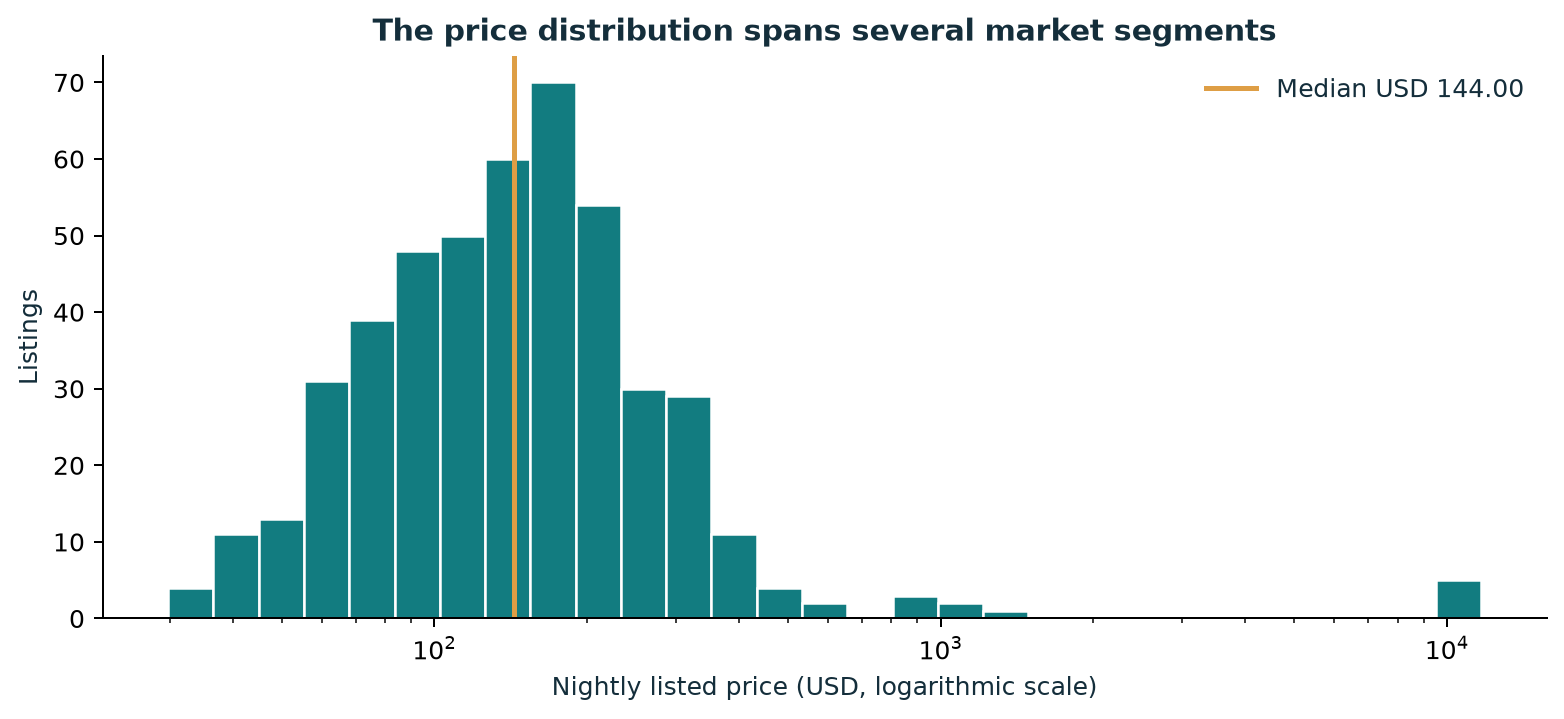

In [5]:
display(Image(filename=str(OUT / 'figures/price_distribution.png'), width=850))

## 4. Availability is not occupancy

The denominator below is known calendar states. No prices are present in this calendar snapshot. Do not copy listing prices onto calendar dates to invent weekend price comparisons or revenue estimates.


In [6]:
con.execute('''SELECT month, listing_days, known_days, available_share, priced_days
FROM mart_calendar_month ORDER BY month''').df()

,month,listing_days,known_days,available_share,priced_days
0,2026-09,7500,7500,0.489600,0
1,2026-10,15500,15500,0.645097,0
2,2026-11,15000,15000,0.730800,0
3,2026-12,15500,15500,0.751226,0
4,2027-01,15500,15500,0.744129,0
5,2027-02,14000,14000,0.767857,0
6,2027-03,15500,15500,0.740581,0
7,2027-04,15000,15000,0.723867,0
8,2027-05,15500,15500,0.725613,0
9,2027-06,15000,15000,0.662867,0


## 5. Statistical results and sensitivity

Tests use one deterministic representative listing per host. Inspect sample sizes, effect sizes, confidence intervals and normality diagnostics in each result. Holm-adjusted primary p-values and trimmed-mean sensitivity p-values refer to different test families and estimands.


In [7]:
pd.DataFrame(results['hypotheses'])[[
    'id','status','p_holm','difference','cohens_d','ci95_low','ci95_high','trimmed_p_holm'
]]

,id,status,p_holm,difference,cohens_d,ci95_low,ci95_high,trimmed_p_holm
0,H1,ok,0.033430,200.140653,0.231037,28.947315,371.333991,8.128146e-16
1,H2,ok,0.000001,0.276053,0.799339,0.174285,0.377821,5.566924e-05
2,H3,ok,0.464678,-119.909776,-0.137262,-445.173658,205.354106,7.323733e-03
3,H4,ok,0.175059,NaN,NaN,NaN,NaN,NaN
4,H5,not estimable,NaN,NaN,NaN,NaN,NaN,NaN


## 6. Evaluate before claiming model value

Group cross-validation stays within training hosts; the test split contains unseen hosts. Imputation and encoding are fitted within training folds. The median baseline wins this experiment; that is useful evidence against premature model deployment.


In [8]:
display(pd.DataFrame(results['models']['scores']))
print('Selected by training CV:', results['models']['selected_model'])
print('Host overlap:', results['models']['host_overlap'])
display(pd.DataFrame(results['models']['neighbourhood_errors']))


,model,cv_mae,cv_mae_std,test_mae,test_rmse,test_mape_pct
0,median_baseline,227.403733,298.899990,92.460500,130.225088,84.613701
1,ridge,477.254296,162.096464,367.816168,472.198905,303.587815
2,extra_trees,335.485335,240.935397,282.230333,772.554430,214.329931
3,hist_gradient_boosting,468.814129,182.940169,238.017696,400.273708,176.195333


Selected by training CV: median_baseline
Host overlap: 0


,neighbourhood,n,mae,mean_residual
0,EIGHTH WARD,3,121.000000,71.666667
1,ELEVENTH WARD,3,83.466667,-83.466667
2,FIFTEENTH WARD,11,158.441818,136.745455
3,FIRST WARD,3,64.490000,-3.290000
4,FOURTEENTH WARD,5,108.018000,63.802000
5,NINTH WARD,5,56.600000,26.200000
6,SIXTH WARD,15,39.276000,-9.316000
7,TENTH WARD,16,93.070000,-75.570000
8,THIRD WARD,4,59.017500,-19.517500
9,THIRTEENTH WARD,8,137.313750,4.186250


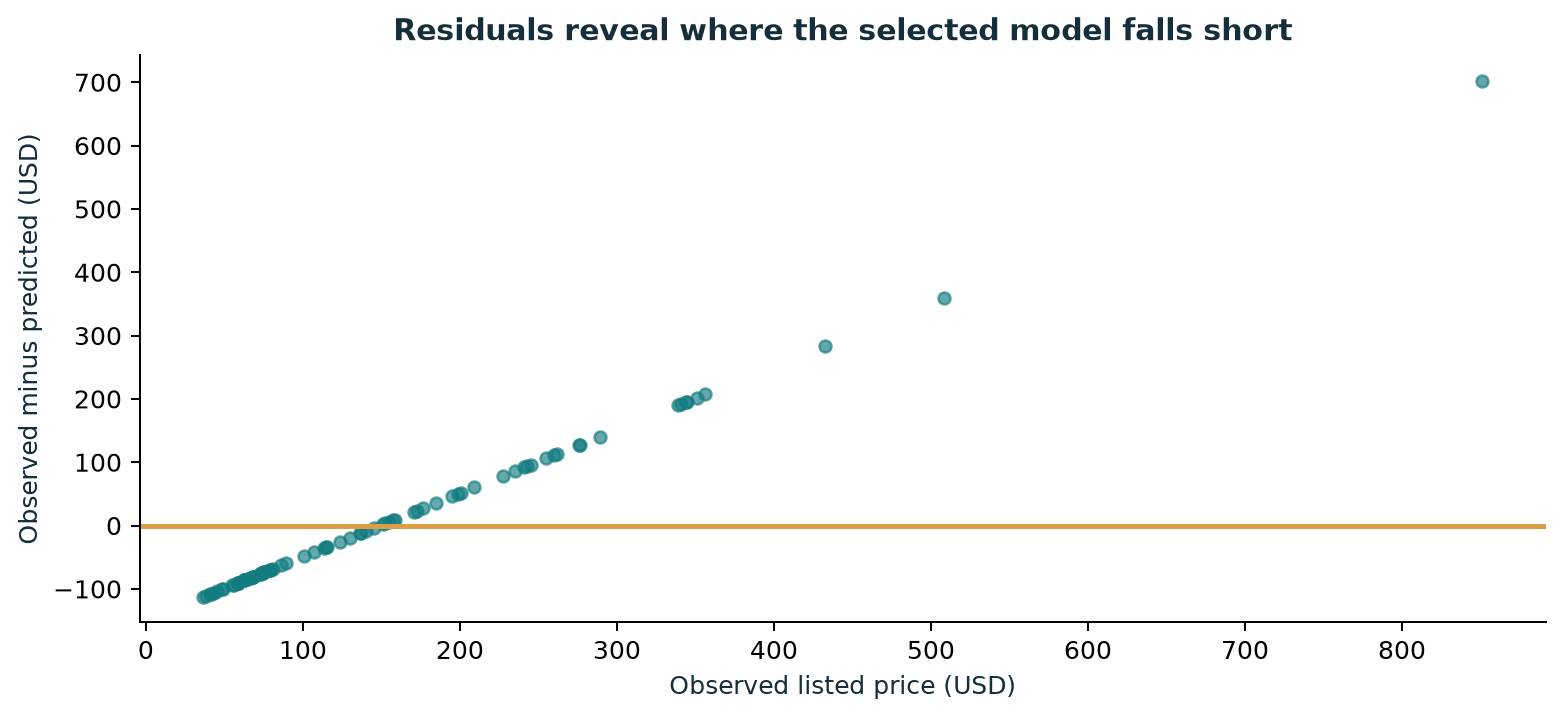

In [9]:
display(Image(filename=str(OUT / 'figures/residuals.png'), width=850))

## 7. Make a reasoned next step

Add another dated snapshot and predeclare a temporal evaluation before experimenting with log-target or robust-loss models. Track changes in missingness, supply and price distributions. A model tuned repeatedly against this same holdout would need a new untouched validation set.

**Your exercise:** add a SQL query for room-type price coverage within each ward, explain its grain, and compare it to the explorer. Then document one engineering change you made independently.

Source: [Inside Airbnb](https://insideairbnb.com/get-the-data/), CC BY 4.0. See the repository AI disclosure and limitations before reusing these findings.


In [10]:
con.close()